<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[7, 5, 10, 4, 7]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0272
3     0.0570
4     0.0805
5     0.1118
6     0.1363
7     0.1662
8     0.1404
9     0.1125
10    0.0833
11    0.0566
12    0.0282
Name: count, dtype: float64


<Axes: >

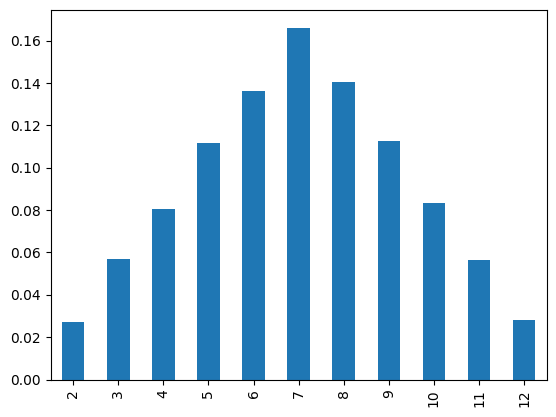

In [7]:
s.plot(kind='bar')

<Axes: >

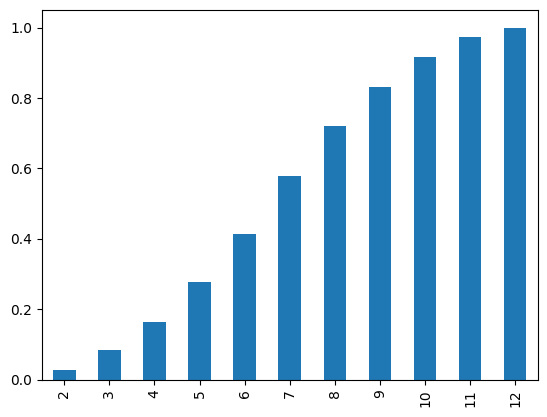

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[36.03293152 50.67684777 50.70016744 47.22020888 42.50846183 43.38741185
 47.56857457 46.38389318 51.07678497 45.30993708 44.92011399 52.47298242
 46.25717315 53.25922966 52.56988581 49.82470926 54.94657453 48.77761083
 49.34833462 52.21970481 50.56400829 51.60277028 45.15313546 48.5845574
 49.25021606 52.89759044 52.2073692  48.62680536 49.6176949  47.40165547
 47.90877062 53.78904562 48.90081208 56.80535906 56.1423479  49.92855159
 50.25297881 57.92019417 50.79791103 52.41979662 51.57995344 46.07408781
 56.5626913  56.25481702 47.0262059  49.22180506 47.02079996 48.07496814
 49.26523828 47.76948241 50.55990191 55.56699797 47.1108519  48.10982156
 54.24655167 46.43717037 48.811431   55.19868948 43.87338879 55.17953769
 61.22233237 58.65671853 50.92030784 52.91493527 43.4676627  58.16870659
 49.25711215 53.69184082 45.62822408 47.29371218 46.20406838 52.23714455
 42.7567523  55.47119048 51.9629836  43.41324146 52.31490832 41.81765747
 54.40288012 47.88565635 56.33859087 45.33475073 50.

In [10]:
sample.mean()

np.float64(49.94752322832961)

(array([  8.,  32.,  92., 206., 256., 212., 130.,  49.,  13.,   2.]),
 array([34.77183577, 38.03039577, 41.28895577, 44.54751577, 47.80607577,
        51.06463577, 54.32319577, 57.58175577, 60.84031577, 64.09887578,
        67.35743578]),
 <BarContainer object of 10 artists>)

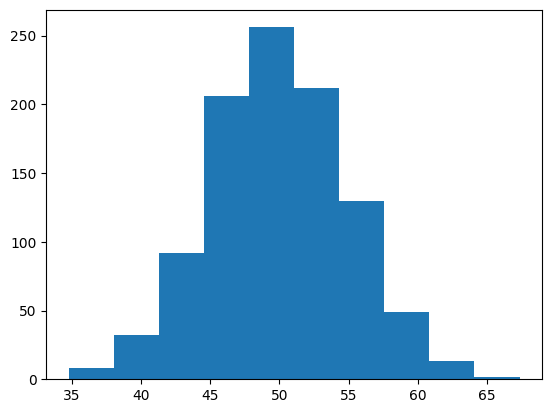

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(34.77183577111451)

In [15]:
sample.max()

np.float64(67.35743577597125)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

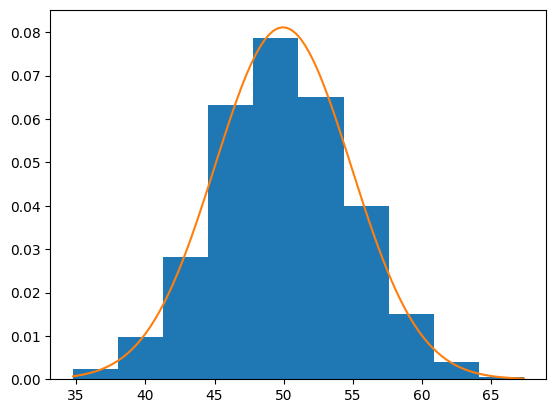

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_1981/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

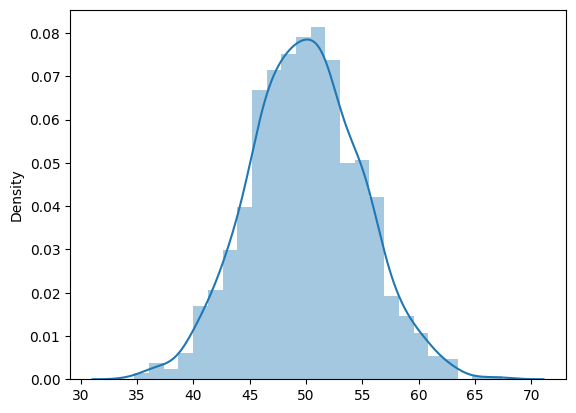

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([20.51708637, 16.53423458, 17.08164382, 22.60822169,  9.4060205 ,
       18.33909958, 18.62760413, 12.08812134, 23.44046235, 14.05774813,
       25.16357381, 22.39647364, 15.87126703, 16.67384379, 14.37716091,
       14.94127852, 23.22433943, 22.14400562, 26.85848866, 15.55030571,
       23.515724  , 24.70101421, 25.07672584, 14.490666  , 26.71669175,
       26.05978599, 12.07057268, 17.79500291, 30.69603511, 18.27101237,
       15.60281191, 25.26236803, 25.29148853, 14.66944193,  9.34334473,
       23.03414089, 17.99215991, 25.37279216, 21.92582924, 22.68831677,
       19.06487382, 21.54331673, 12.75574425, 18.84085854, 16.72065712,
       24.94228554, 15.57538714, 24.13643804, 13.83406694, 16.73817611,
       25.69511789, 24.45360732, 20.96721324, 17.79500208, 11.2734786 ,
       18.07312873, 15.62240379, 14.92649568, 17.03214864, 24.50294271,
       23.99834294, 21.09957971,  6.93549537, 21.84102268, 17.20165393,
       14.46830656, 20.94668773, 17.54235955, 22.53075454, 21.55

(array([ 2.,  0.,  1.,  1.,  3.,  2., 10., 10.,  8., 16., 23., 21., 32.,
        20., 17., 26., 21., 21., 25., 14.,  6.,  9.,  6., 11., 13., 15.,
        25., 30., 40., 36., 45., 55., 61., 61., 59., 63., 48., 54., 31.,
        20., 14.,  9.,  7.,  2.,  0.,  3.,  2.,  1.,  0.,  1.]),
 array([ 4.54552911,  5.62492468,  6.70432025,  7.78371582,  8.8631114 ,
         9.94250697, 11.02190254, 12.10129811, 13.18069368, 14.26008925,
        15.33948483, 16.4188804 , 17.49827597, 18.57767154, 19.65706711,
        20.73646268, 21.81585826, 22.89525383, 23.9746494 , 25.05404497,
        26.13344054, 27.21283611, 28.29223169, 29.37162726, 30.45102283,
        31.5304184 , 32.60981397, 33.68920955, 34.76860512, 35.84800069,
        36.92739626, 38.00679183, 39.0861874 , 40.16558298, 41.24497855,
        42.32437412, 43.40376969, 44.48316526, 45.56256083, 46.64195641,
        47.72135198, 48.80074755, 49.88014312, 50.95953869, 52.03893427,
        53.11832984, 54.19772541, 55.27712098, 56.35651655,

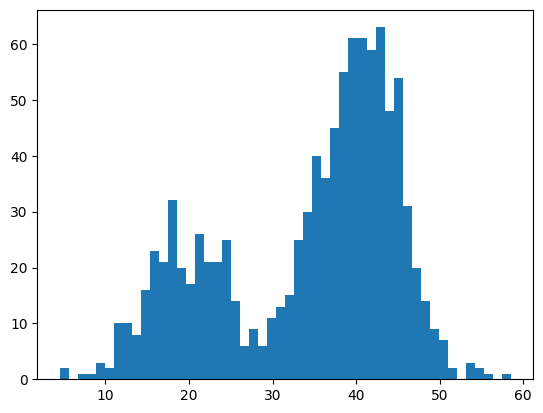

In [22]:
plt.hist(sample,bins=50)

In [23]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [24]:
dataset=sns.load_dataset("iris")

In [25]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

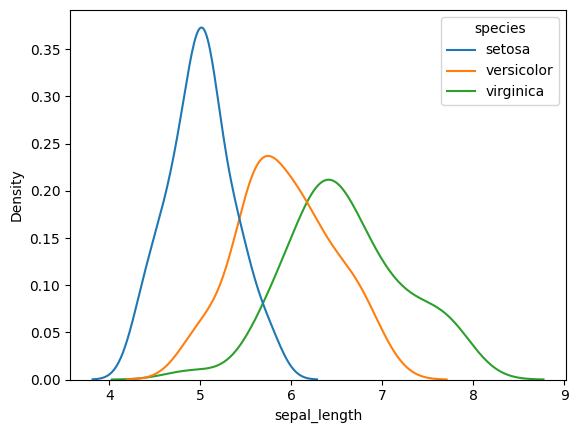

In [26]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

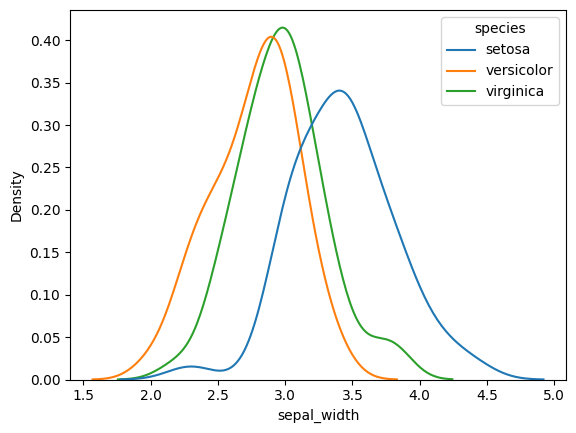

In [27]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

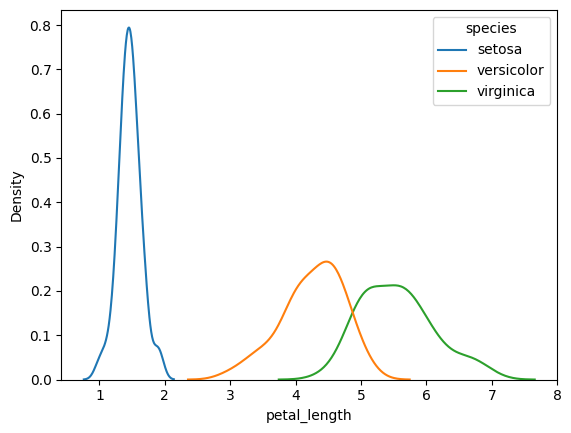

In [28]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

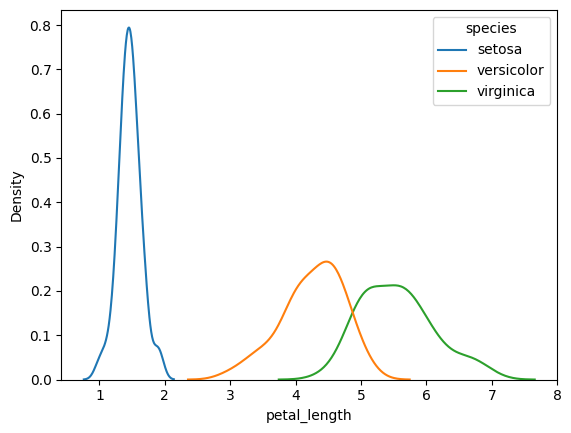

In [29]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [30]:
tips=sns.load_dataset("tips")

In [31]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

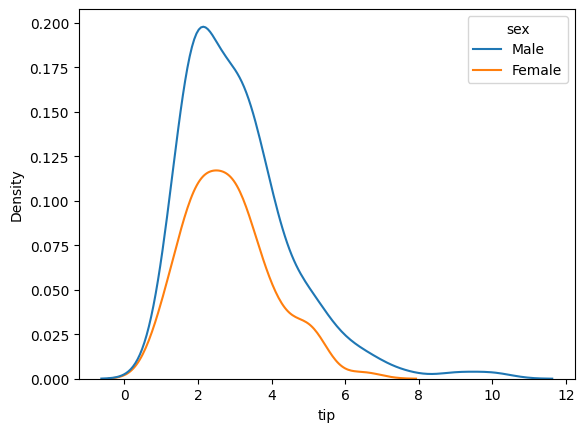

In [32]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

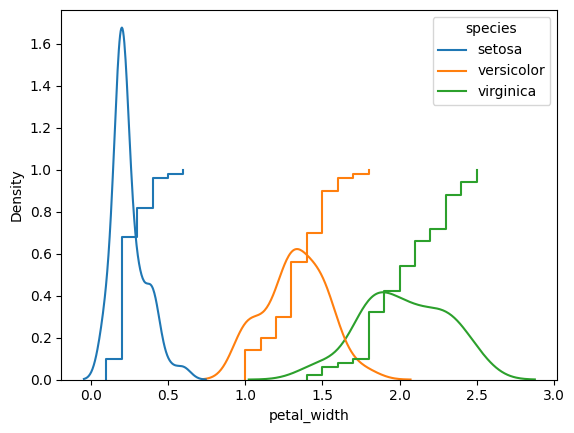

In [33]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [34]:
#contour plots

How to find distribution is normal or not?

In [35]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

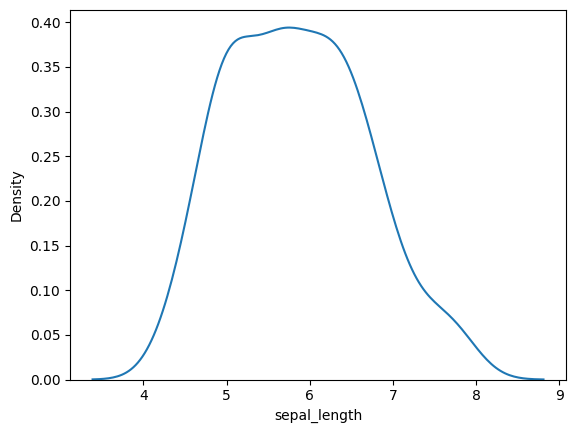

In [36]:
sns.kdeplot(iris["sepal_length"])

In [37]:
temp=sorted(iris['sepal_length'].tolist())

In [38]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [39]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [40]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

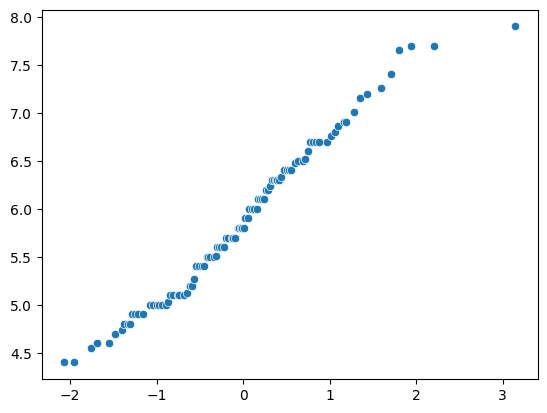

In [41]:
sns.scatterplot(x=x_quant,y=y_quant)

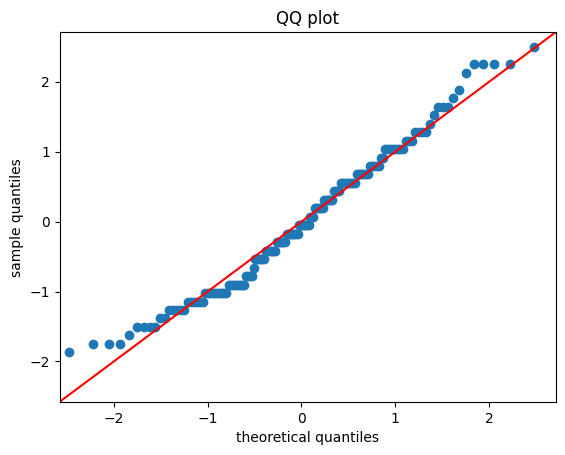

In [42]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [43]:
import scipy.stats as stats

In [44]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([ 98., 104., 112., 105., 113.,  83.,  99.,  74., 102., 110.]),
 array([2.40456857e-04, 1.00174402e-01, 2.00108347e-01, 3.00042292e-01,
        3.99976237e-01, 4.99910182e-01, 5.99844127e-01, 6.99778072e-01,
        7.99712017e-01, 8.99645962e-01, 9.99579907e-01]),
 <BarContainer object of 10 artists>)

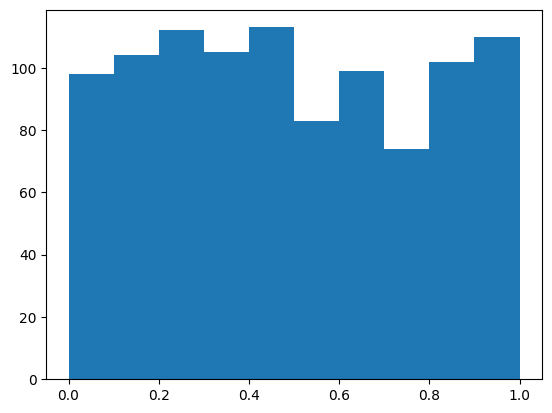

In [45]:
plt.hist(x)

PARETO DISTRIBUTION

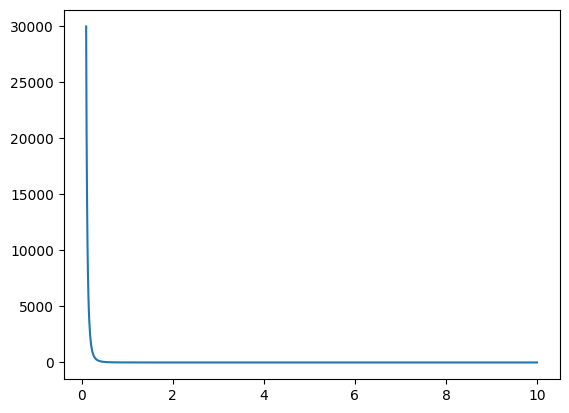

In [46]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

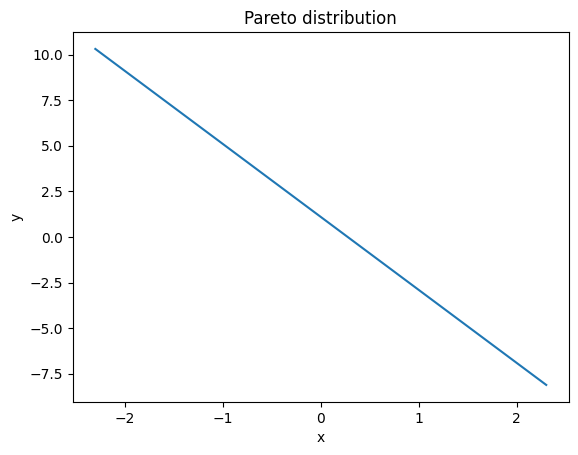

In [47]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [48]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([942.,  36.,   9.,   8.,   2.,   1.,   0.,   0.,   1.,   1.]),
 array([ 1.00030986,  4.20156187,  7.40281387, 10.60406588, 13.80531788,
        17.00656989, 20.2078219 , 23.4090739 , 26.61032591, 29.81157791,
        33.01282992]),
 <BarContainer object of 10 artists>)

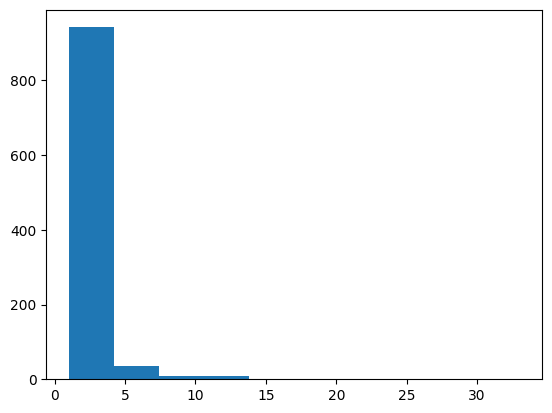

In [49]:
plt.hist(x)

In [50]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

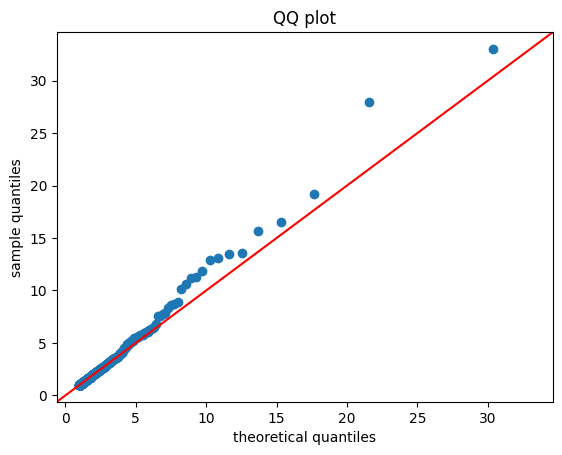

In [51]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [77]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [53]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [54]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [55]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Cycle Count,0


In [56]:
x=df.iloc[:,1:4]
y=df.iloc[:,0]

In [57]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)
'''What does train_test_split() do?
train_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:
- Training data: Used to train the machine-learning model.
- Testing data: Used to check how well the model performs on data it hasn't trained on.

random_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data.'''

"What does train_test_split() do?\ntrain_test_split() is a function from sklearn.model_selection that divides your dataset into two parts:\n- Training data: Used to train the machine-learning model.\n- Testing data: Used to check how well the model performs on data it hasn't trained on.\n\nrandom_state=42 is optional. It makes the random split reproducible, so you get the same split when you run the code again with the same data."

/tmp/ipykernel_1981/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

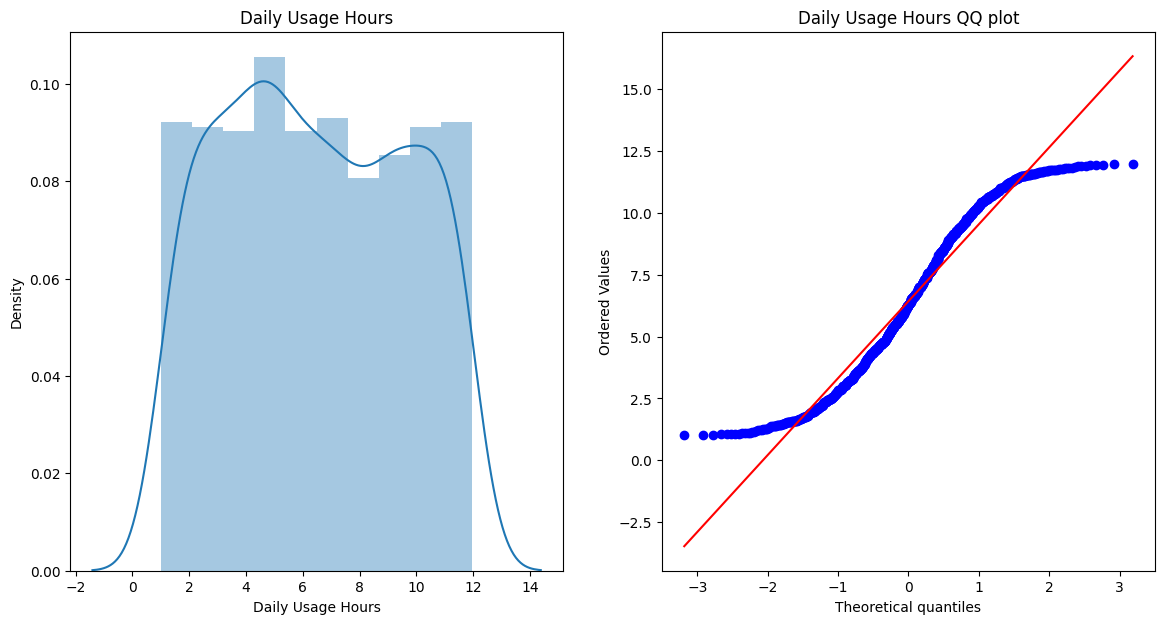

In [58]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

/tmp/ipykernel_1981/882698.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Cycle Count'])


Text(0.5, 1.0, 'Cycle Count QQ plot')

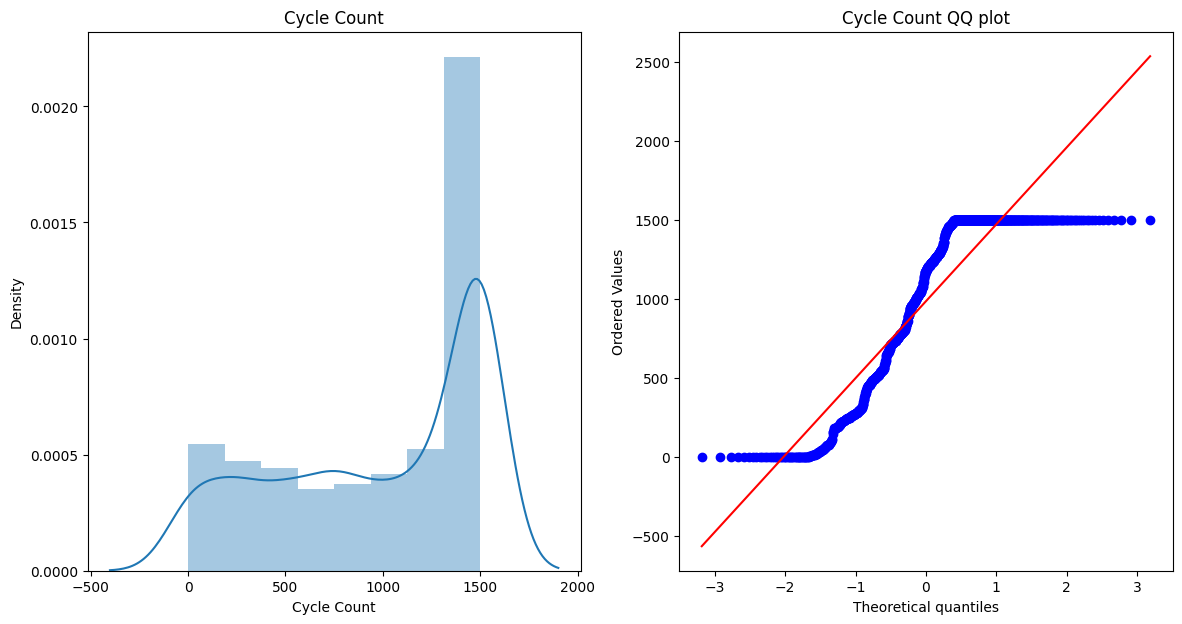

In [59]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Cycle Count'])
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")


In [60]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [61]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 2) (1200,)


In [62]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Cycle Count
0           9.797617         1267
1           7.101557         1500
2          10.085255         1500
3           7.946047         1153
4           9.628460         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Cycle Count           562
dtype: int64


In [63]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Cycle Count,0.952206


In [64]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.26666666666666666
Accuracy DT 0.7125


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [65]:
trf=FunctionTransformer(np.log1p)

In [66]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

      Daily Usage Hours  Cycle Count
845            2.273042     7.284821
497            0.905877     6.645091
1100           1.762339     7.313887
1066           2.312655     7.313887
522            2.147233     7.313887
...                 ...          ...
475            1.644545     7.313887
690            2.173516     7.138073
22             1.334220     7.104965
1176           2.209426     7.147559
223            2.438010     0.000000

[960 rows x 2 columns]
     Daily Usage Hours  Cycle Count
182           2.115454     6.841615
264           1.746003     7.313887
107           2.383780     6.198479
90            1.766325     6.878326
334           1.604657     1.098612
..                 ...          ...
499           1.842832     6.610696
408           2.440249     7.313887
669           1.465384     7.313887
466           0.763381     7.313887
20            1.058194     7.313887

[240 rows x 2 columns]


In [67]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.5291666666666667
Accuracy DT 0.7125


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[ 6  5  6  6  5  3  6  4  9  8  4  5  5  5  2  8  5  4  4  5  4  8  6  5
  6  6  5  3  7  4  5  2  4  7  5  5  7  6  4  4  4  7  6  4  6  5  6  4
  4  5  5  5  4  3  5  6  3  4  4  6  3  4  3  5  5  2  6  4  5  5  3  6
  6  5  6  8  6  5  9  3  8  5  6  5  3  6  2  7  6  5  5  3  5  4  7  4
  3  4  4  4  3  6  6  8  3  7  5  3  6  2  5  7  4  5  4  5  4  5  5  4
  8  7  4  4  7  5  5  4  5  5  2  3  6  7  8  6  5  3  2  4  6  4  6  3
  4  8  5  5  4  5  2  8  5  7  4  2  7  3  4  4  6  5  7  7  4  4  5  5
  7  8  4  5  5  4  4  5  5  4  8  5  5  5  7  3  5  4  6  4  6  6  5  4
  5  4  5  7  7  5  4  6  3  6  2  2  5  6  6  3  6  5  4  2  6  5  3  3
  3  5  4  6  6  5  5  6  7  7  6  7  6  5  3  3  4  5  3  5  6  4  7  2
  8  6  3  4  6  6  8  7  8  6  3  7  4  7  5  5  5  4  8  7  4  4  5  6
  4  5  7  3  5  5  3  5  2  5  5  5  4  6  7  5  4  3  5  4  5  6  6  6
  4  4  6  2  5  5  7  2  4  5  5  3  7  4  5  5  7  5  6  5  4  4  5  3
  4  6  7  6  6  6  5  7  6  5  4  5  3  8  4  5  3

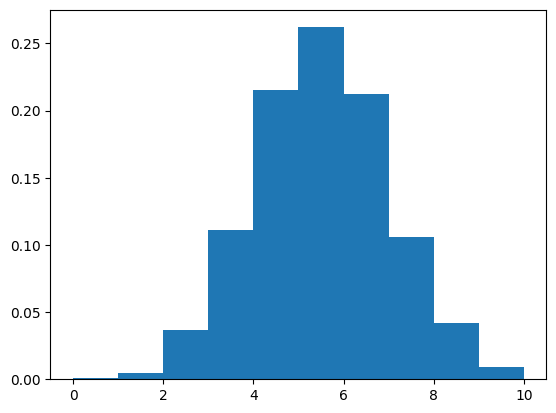

In [68]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [69]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [70]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.49847889, 0.51116151, 0.47150601, ..., 0.49443435, 0.50693504,
       0.52140709])

In [71]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

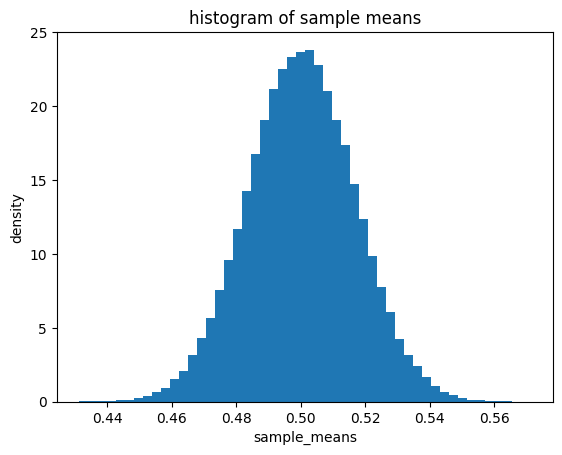

In [72]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [73]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

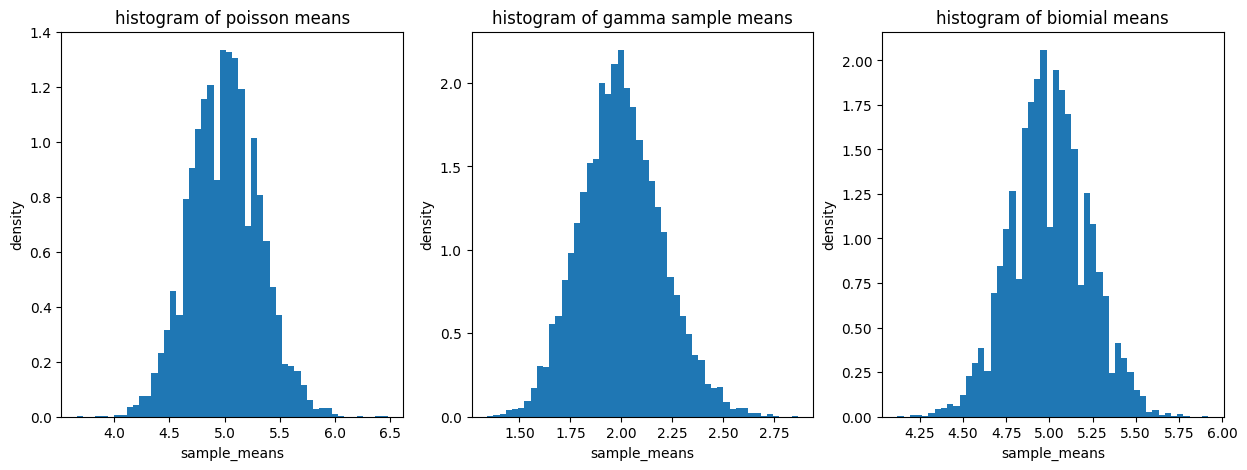

In [74]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [75]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 2.0120259477308173
Emperical variance: 0.0654439069201345


CASE STUDY

In [78]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [79]:
battery_csv.shape

(1200, 11)

In [84]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
45,4,6.953971,0,74217,1033,43.350537,37.409842,59.897610,29.214204,62684.685284,83.790276
1016,4,6.981658,0,75285,956,50.727414,41.524384,63.543631,26.162607,66038.090868,86.086536
557,6,4.384470,1,69312,1464,68.736428,67.692276,92.887033,34.113041,54840.797488,78.391510
188,4,7.106472,0,58450,981,52.841473,35.784365,73.903020,31.026673,48369.797795,82.992967
342,7,6.986831,0,67671,1500,48.018411,30.243129,52.432501,28.032037,51981.259692,77.253011
...,...,...,...,...,...,...,...,...,...,...,...
872,1,3.511644,0,62118,331,33.816780,25.930682,54.812034,28.768606,57848.515254,92.849685
1084,3,7.680569,0,66573,755,54.322107,33.365260,79.989084,31.835020,58401.052658,86.103573
465,8,10.393372,0,48770,1500,64.015533,46.681316,76.696336,32.785491,33570.397309,68.259875
395,7,2.216640,0,65774,1500,22.264925,23.670063,53.014205,29.887073,50812.169008,77.387769


In [85]:
d['Daily Usage Hours'].mean()

np.float64(6.43507813125098)

<Axes: ylabel='Density'>

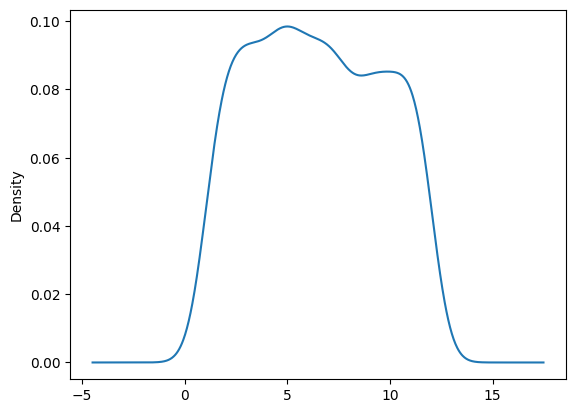

In [95]:
d['Daily Usage Hours'].plot(kind='density')

In [97]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
260,10.307366
250,9.197362
961,5.281295
927,9.580529
676,11.484321
867,9.318115
635,3.665891
750,10.283928
998,11.568209
1196,10.547996


In [99]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[4.485945514926872,
 2.3579485239139064,
 2.851064473584841,
 3.2637381468836386,
 3.839184074907562,
 1.6131493894618592,
 5.517508963113111,
 1.4329806780170244,
 8.331741743623384,
 9.463868373637125,
 11.816748452556492,
 3.494498878516102,
 4.588425576790247,
 7.948946601592424,
 11.3917811983973,
 11.73356700403826,
 11.149096535639291,
 11.289339386345786,
 4.9155355081770455,
 3.0914164295057622,
 1.70504182139793,
 6.622032036196378,
 6.641622165357945,
 4.727058306650881,
 5.50640156221771,
 7.886601798788814,
 3.612316356863224,
 2.2384951318211392,
 3.1635701704410537,
 10.891738101181229,
 9.429819344151175,
 2.2084942511486125,
 1.2634089179753183,
 1.897324181725025,
 10.761669889073962,
 11.793833351304045,
 6.560728708958393,
 2.199149772050216,
 11.005033203133522,
 2.9898109151678813,
 2.3872685461295164,
 5.608667511574768,
 2.5103003598712723,
 11.62415551690166,
 3.185090345871464,
 4.031234539400963,
 5.891840545441694,
 8.565461270023082,
 9.157900161970778,
 7.

In [100]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [101]:
samples

[[2.467579690755278,
  10.737627665783217,
  2.3474764816258813,
  7.2509547789564515,
  6.041998273689368,
  11.261544591392964,
  9.46721285142796,
  2.807155275996502,
  2.0666223806196724,
  4.902770186220275,
  5.661471319240158,
  11.019088911549469,
  4.044295451464395,
  3.6380194742724927,
  10.566146532933884,
  2.5531896989090344,
  4.471965369038675,
  7.635699649524328,
  7.010477816333453,
  3.704321867427403,
  6.188144398256549,
  4.740048246658814,
  2.947904809370188,
  3.0273153664510897,
  5.080710838513859,
  7.711187142398581,
  10.655243453488874,
  10.802541009728603,
  4.1104200276610845,
  4.524414147542364,
  7.4027714423664595,
  8.514257142953511,
  7.287684144312382,
  2.173830010125897,
  3.1528390410961395,
  11.893136876434356,
  9.10845655352303,
  1.6046293752380427,
  5.644114572687458,
  3.606163932863958,
  1.4966650085352111,
  5.3757278502200805,
  3.569240971754721,
  11.741021823789511,
  7.361957394281941,
  1.4847244772741952,
  9.26977979945

In [105]:
samples=np.array(samples)
samples

array([[ 2.46757969, 10.73762767,  2.34747648, ...,  9.16606931,
         7.60641517,  5.34558672],
       [10.3933717 ,  2.01694469,  2.25362476, ...,  8.37477767,
         7.25095478,  4.33724098],
       [ 3.3489714 ,  9.45967246,  5.32652737, ...,  9.36006099,
         1.63131028,  3.47677127],
       ...,
       [ 3.24394064,  1.22151634,  2.44855594, ...,  4.55090773,
         3.62626948,  1.43792583],
       [11.47625428,  8.98693337,  6.24681732, ...,  6.75741508,
         2.56812211,  9.61725942],
       [ 5.54868183,  9.10120492,  8.13551249, ...,  1.96567061,
        11.12589474,  4.77222629]])

In [109]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [111]:
sampling_means.mean()

np.float64(6.516504758285222)

In [112]:
sampling_means.std()/np.sqrt(50)

np.float64(0.05667202402389667)

<Axes: ylabel='Density'>

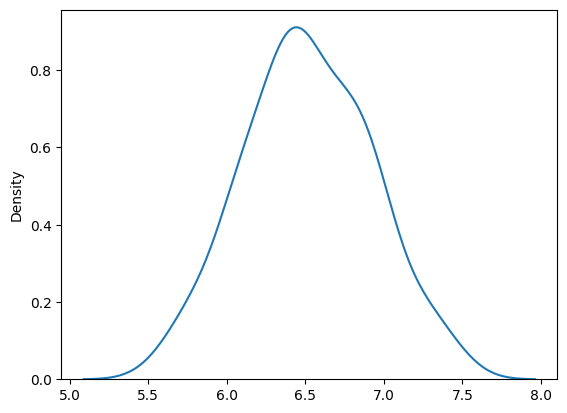

In [110]:
sns.kdeplot(data=sampling_means)

In [116]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.403160710237429 - 6.6298488063330145
